## Module 3: Computational Drug Discovery Project

Liam Sunshine and Aymen Akram

## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  
The below sections should be addressed in your Project Report as a Jupyter notebook, based on Module3_Project_Template.ipynb. All groups submit a Project Report, only those in the Sullivan Company have Oral Presentations (**all due 11/17**).

### Disease Background

Obesity is defined in adults as a body mass index (BMI) of 30 kg/m² or greater and is associated with increased risks of cardiovascular disease, type 2 diabetes, certain cancers, and premature mortality (CDC, 2025). Its prevalence is influenced by multiple factors, including increased access to calorie-dense foods, sedentary lifestyles, genetic predisposition, and environmental conditions. Current treatments include dietary modifications, increased physical activity, behavioral interventions, bariatric surgery, and medications such as semaglutide, a GLP-1 receptor agonist that reduces appetite and promotes weight loss (NIDDK, n.d.). Although GLP-1 medications have demonstrated substantial effectiveness, challenges remain, including gastrointestinal side effects, treatment costs, nutritional concerns associated with reduced food intake, and weight regain following discontinuation (Wilding et al., 2021; Wilding et al., 2022). Maintaining adequate nutrition, cardiovascular exercise, and resistance training alongside pharmacological treatment may support long-term health and preservation of muscle mass. These limitations highlight the need for improved obesity treatments. Cavalitide, a proposed GLP-1 receptor agonist, is being investigated through computational modeling to evaluate its receptor-binding characteristics, pharmacokinetics, and potential advantages over existing medications.

## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.


### Receptor-Binding Model and Methodology

To evaluate Cavalitide's pharmacodynamic properties, experimental concentration-response data were fitted to a competitive two-agonist model of GLP-1 receptor activation. The model accounts for both endogenous GLP-1 and Cavalitide binding to GLP1R.

The fraction of active receptors was modeled as:

$$
F_{act}=\frac{K_{d2}[GLP1]+K_{d1}[Drug]}{K_{d1}K_{d2}+K_{d2}[GLP1]+K_{d1}[Drug]}
$$

Here, $K_{d1}=0.17$ nM is the dissociation constant of endogenous GLP-1, $[GLP1]=0.015$ nM represents fasting GLP-1 concentration, and $K_{d2}$ is the fitted dissociation constant of Cavalitide or semaglutide. Experimental data provided for the project were fitted using brute-force optimization and SciPy's `curve_fit` function. Both methods minimized the sum of squared errors (SSE) between the observed and predicted receptor activation values.


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Endogenous GLP-1 parameters (nM)
Kd1 = 0.17
L1 = 0.015

# Two-agonist receptor activation model
def Fact(L1, L2, Kd1, Kd2):
    return (Kd2 * L1 + Kd1 * L2) / (
        Kd1 * Kd2 + Kd2 * L1 + Kd1 * L2
    )

# Load experimental data
cavalitide_data = np.loadtxt(
    "cavalitide_data.csv", delimiter=",", skiprows=1
)
semaglutide_data = np.loadtxt(
    "semaglutide_data.csv", delimiter=",", skiprows=1
)

# Fit dissociation constants using two methods
def fit_drug(data):
    concentrations = data[:, 0]
    activation = data[:, 1]

    # Brute-force search
    candidates = np.logspace(-3, 2, 100)
    errors = [
        np.sum(
            (activation - Fact(L1, concentrations, Kd1, k))**2
        )
        for k in candidates
    ]
    Kd_brute = candidates[np.argmin(errors)]

    # Nonlinear least-squares fitting
    popt, pcov = curve_fit(
        lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
        concentrations,
        activation,
        p0=[0.1],
        bounds=(0, np.inf)
    )
    Kd_fit = popt[0]

    # Sum of squared errors
    SSE = np.sum(
        (activation - Fact(L1, concentrations, Kd1, Kd_fit))**2
    )

    return Kd_brute, Kd_fit, SSE

cav_brute, cav_Kd, cav_SSE = fit_drug(cavalitide_data)
sem_brute, sem_Kd, sem_SSE = fit_drug(semaglutide_data)

print("Cavalitide:")
print(f"  Brute-force Kd = {cav_brute:.4f} nM")
print(f"  Curve-fit Kd   = {cav_Kd:.4f} nM")
print(f"  SSE            = {cav_SSE:.5f}")

print("\nSemaglutide:")
print(f"  Brute-force Kd = {sem_brute:.4f} nM")
print(f"  Curve-fit Kd   = {sem_Kd:.4f} nM")
print(f"  SSE            = {sem_SSE:.5f}")

print(f"\nKd ratio (semaglutide/Cavalitide): "
      f"{sem_Kd / cav_Kd:.2f}")


Cavalitide:
  Brute-force Kd = 0.0739 nM
  Curve-fit Kd   = 0.0770 nM
  SSE            = 0.00515

Semaglutide:
  Brute-force Kd = 0.3352 nM
  Curve-fit Kd   = 0.3498 nM
  SSE            = 0.00443

Kd ratio (semaglutide/Cavalitide): 4.54


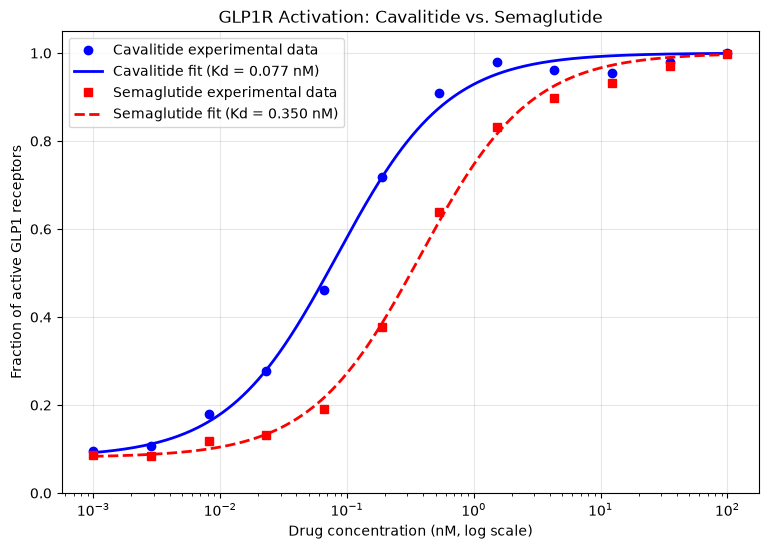

In [4]:

# Drug concentration range (nM)
L2 = np.logspace(-3, 2, 500)

plt.figure(figsize=(9, 6))

# Cavalitide experimental data and fitted curve
plt.semilogx(
    cavalitide_data[:, 0],
    cavalitide_data[:, 1],
    "o",
    color="blue",
    label="Cavalitide experimental data"
)

plt.semilogx(
    L2,
    Fact(L1, L2, Kd1, cav_Kd),
    "-",
    color="blue",
    linewidth=2,
    label=f"Cavalitide fit (Kd = {cav_Kd:.3f} nM)"
)

# Semaglutide experimental data and fitted curve
plt.semilogx(
    semaglutide_data[:, 0],
    semaglutide_data[:, 1],
    "s",
    color="red",
    label="Semaglutide experimental data"
)

plt.semilogx(
    L2,
    Fact(L1, L2, Kd1, sem_Kd),
    "--",
    color="red",
    linewidth=2,
    label=f"Semaglutide fit (Kd = {sem_Kd:.3f} nM)"
)

plt.xlabel("Drug concentration (nM, log scale)")
plt.ylabel("Fraction of active GLP1 receptors")
plt.title("GLP1R Activation: Cavalitide vs. Semaglutide")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("Task1_GLP1R_Binding.png",
            dpi=300, bbox_inches="tight")
plt.show()


### Results and Interpretation

For Cavalitide, the brute-force search estimated a dissociation constant of 0.0739 nM, while nonlinear least-squares fitting with SciPy's `curve_fit` produced a value of 0.0770 nM. The small difference is consistent with the limited resolution of the brute-force search, which tested 100 candidate values. The curve-fit estimate of **0.0770 nM** will be used in the subsequent PKPD model.

Applying the same fitting procedure to the semaglutide dataset produced a dissociation constant of **0.3498 nM**. This fitted estimate differs slightly from the 0.38 nM reference value used in the earlier semaglutide modeling exercise. Here, the comparison uses the fitted values for both drugs.

Semaglutide's fitted Kd is approximately **4.54 times** Cavalitide's fitted Kd. Because a lower Kd indicates greater receptor-binding affinity, Cavalitide has greater modeled affinity for GLP1R. Its concentration-response curve is shifted to the left, meaning that a lower Cavalitide concentration produces the same modeled receptor activation under the same endogenous GLP-1 conditions.

The plotted curves visually follow the experimental data, with sums of squared errors of approximately **0.00515 for Cavalitide** and **0.00443 for semaglutide**. These results support the model's description of the supplied concentration-response data.

A potential advantage of Cavalitide's greater affinity is that the desired receptor activation could be achieved at a lower free drug concentration. However, this does not by itself establish that a smaller administered dose would be sufficient, because drug exposure also depends on absorption, distribution, and elimination.

A potential dosing disadvantage is that using the same free drug concentration as semaglutide would produce higher modeled receptor activation, potentially exceeding the intended activation target. Cavalitide's dosing strategy may therefore require adjustment. This is a model-based consideration, not evidence that Cavalitide causes more adverse effects.

Finally, greater binding affinity does not establish greater clinical weight loss or improved safety. This simplified model treats receptor binding as activation and does not capture differences in signaling efficacy or clinical outcomes. Pharmacokinetics and dosing will be evaluated in Tasks 2 and 3.


### Application to the Combined PKPD Model

The fitted Cavalitide dissociation constant of 0.0770 nM will be incorporated into the combined pharmacokinetic-pharmacodynamic (PKPD) model in Task 3. By combining the receptor activation equation with simulated free drug concentrations in the bloodstream, we can predict how GLP1R activation changes over time following repeated dosing. This will allow us to investigate dosing adjustments needed to approach 90% receptor activation at steady state.


## Task 2: Simulate the pharmacokinetics of Cavalitide treatment
Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide. 

1. Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).  Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.
2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.
3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
# ===== choose product: 'Ozempic' or 'Wegovy' =====
#drug = 'Ozempic'
drug = 'Wegovy'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                                        depot='gut (oral)'),

    'Cavalitide': dict(Favailable=0.01,
                      ka=0.006,
                      D=21,
                      interval=24,
                      n_doses=100,
                      depot='gut (oral)'),
}
p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, Euler step size

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]


def simulate(D, n_doses, interval, dt):
    """Repeated dosing every interval h; returns time (h),
    depot amount (mg), and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))

    for i in range(n_doses):
        y[0] += Favailable * D
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)

        # Use solve_ivp instead of explicit Euler's method
        sol = solve_ivp(
            ODEfunc,
            (t_seg[0], t_seg[-1]),
            y,
            t_eval=t_seg
        )

        y_seg = sol.y

        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()

    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9

    return t, Asc_out, Cc_nM

We used the provided pharmacokinetic model and replaced the explicit Euler method with scipy.integrate.solve_ivp to solve the differential equations. This tracks the amount of drug in the depot and its concentration in the blood over time. We also defined the parameters for Ozempic, Wegovy, and Cavalitide, including their absorption rates, doses, and dosing intervals.

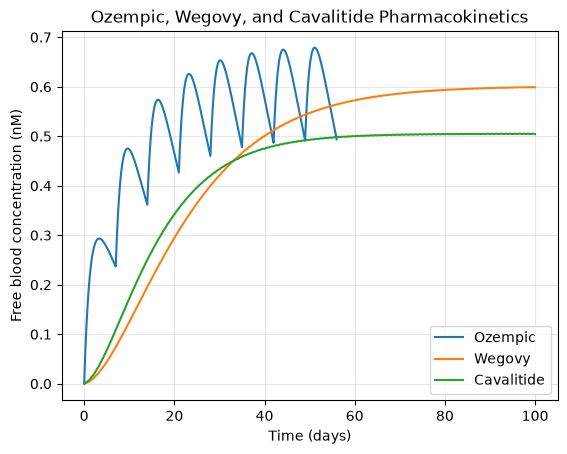

In [2]:
# --- compare Ozempic and Wegovy ---
plt.figure()

for drug in ['Ozempic', 'Wegovy', 'Cavalitide']:
    p = products[drug]
    Favailable = p['Favailable']
    ka = p['ka']

    t, Asc, Cc = simulate(
        p['D'],
        p['n_doses'],
        p['interval'],
        dt
    )

    plt.plot(t / 24, Ffree * Cc, label=drug)

plt.xlabel("Time (days)")
plt.ylabel("Free blood concentration (nM)")
plt.title("Ozempic, Wegovy, and Cavalitide Pharmacokinetics")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

We compared the blood concentrations of Ozempic, Wegovy, and Cavalitide over time. Ozempic had repeated peaks and decreases because it was given weekly, while Wegovy and Cavalitide increased more gradually because they were taken daily. Cavalitide reached steady state faster than Wegovy because it had a higher absorption rate. Since we reduced Cavalitide's dose to 21 mg, it also reached a lower steady state concentration.

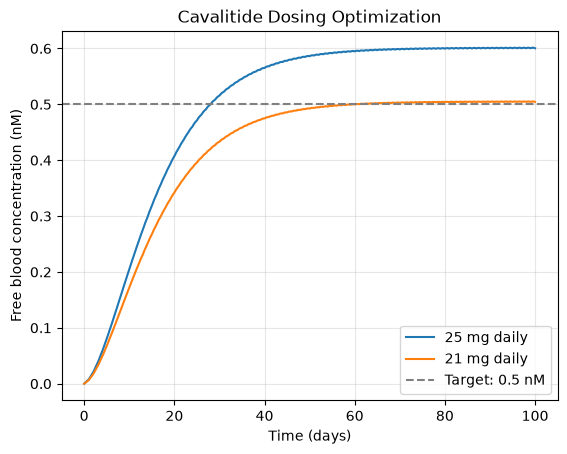

In [3]:
# --- compare original and optimized Cavalitide dosing ---
plt.figure()

for dose in [25, 21]:
    Favailable = products['Cavalitide']['Favailable']
    ka = products['Cavalitide']['ka']

    t, Asc, Cc = simulate(
        dose,
        products['Cavalitide']['n_doses'],
        products['Cavalitide']['interval'],
        dt
    )

    plt.plot(t / 24, Ffree * Cc, label=f"{dose} mg daily")

plt.axhline(y=0.5, color='gray', linestyle='--', label='Target: 0.5 nM')
plt.xlabel("Time (days)")
plt.ylabel("Free blood concentration (nM)")
plt.title("Cavalitide Dosing Optimization")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


We decreased the daily dose from 25 mg to 21 mg while keeping the dosing interval and absorption rate the same. We did this because the original dose gave us a steady state free blood concentration of about 0.6 nM, which was higher than our goal of 0.5 nM. After decreasing the dose to 21 mg, the concentration got closer to 0.5 nM, so we were able to reach our target.

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM concentration of Cavalitide in your patients. Now it’s time to further customize the dosing for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of activated receptors changes over time.

1. Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your optimized Kd) into your cavalitidePK.py model. Let’s call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment. 
2. Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days).  Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.


## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

## AI Usage Statement:
*This is where you will provide a short description on whether AI (and which AI) was used for any of the sections above and whether it helped or why it did not help.*
- *Example statement: "We used Claude Code to generate our linear regression plot. At first, it did not include an R^2 calculation, so we added it to the code afterwards."*

## GitHub Repository Link:
*Please provide the link to your shared GitHub repository that includes this notebook and any other scripts, notebooks, or data that you used for this project.*


## References:

Centers for Disease Control and Prevention. (2025, December 4). How overweight and obesity impacts your health. https://www.cdc.gov/healthy-weight-growth/food-activity/overweight-obesity-impacts-health.html

National Institute of Diabetes and Digestive and Kidney Diseases. (n.d.). Prescription medications to treat overweight & obesity. https://www.niddk.nih.gov/health-information/weight-management/prescription-medications-treat-overweight-obesity

Wilding, J. P. H., et al. (2021). Once-weekly semaglutide in adults with overweight or obesity. New England Journal of Medicine, 384(11), 989–1002. https://doi.org/10.1056/NEJMoa2032183

Wilding, J. P. H., et al. (2022). Weight regain and cardiometabolic effects after withdrawal of semaglutide: The STEP 1 trial extension. Diabetes, Obesity and Metabolism, 24(8), 1553–1564. https://doi.org/10.1111/dom.14725

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*